In [1]:
!pip -q install fastapi uvicorn pandas numpy matplotlib seaborn requests

In [2]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
from pathlib import Path

np.random.seed(42)

Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

def generate_traffic_data(n_records):
    locations = [
        "Clock Tower",
        "Rajpur Road",
        "ISBT",
        "Railway Station",
        "Prem Nagar",
        "Pacific Mall"
    ]

    start_time = datetime(2026, 10, 1, 6, 0)

    timestamps = [
        start_time + timedelta(minutes=15 * np.random.randint(0, 96))
        for _ in range(n_records)
    ]

    location = np.random.choice(locations, n_records)
    vehicle_count = np.random.randint(20, 250, n_records)

    avg_speed = np.clip(
        55 - vehicle_count * 0.18
        + np.random.normal(0, 5, n_records),
        5, 60
    )

    df = pd.DataFrame({
        "record_id": range(1, n_records + 1),
        "location": location,
        "timestamp": timestamps,
        "vehicle_count": vehicle_count,
        "avg_speed": np.round(avg_speed, 2)
    })

    return df

traffic_df = generate_traffic_data(10000)

traffic_df.to_csv("data/traffic.csv", index=False)

print("Dataset generated successfully!")
print("Total records:", len(traffic_df))
display(traffic_df.head())

Dataset generated successfully!
Total records: 10000


,record_id,location,timestamp,vehicle_count,avg_speed
0,1,Prem Nagar,2026-10-01 18:45:00,191,15.16
1,2,Prem Nagar,2026-10-02 05:00:00,36,52.85
2,3,Pacific Mall,2026-10-01 09:30:00,206,17.14
3,4,Rajpur Road,2026-10-01 23:45:00,160,30.65
4,5,Rajpur Road,2026-10-01 21:00:00,71,40.10


In [3]:

from collections import defaultdict
import pandas as pd
import time
import json
from pathlib import Path

def map_traffic_records(df):
    mapped_data = []

    for _, row in df.iterrows():

        timestamp = pd.to_datetime(row["timestamp"])
        hour = timestamp.strftime("%Y-%m-%d %H:00")

        key = (row["location"], hour)

        value = {
            "vehicle_count": int(row["vehicle_count"]),
            "speed": float(row["avg_speed"]),
            "records": 1
        }

        mapped_data.append((key, value))

    return mapped_data

def shuffle_and_group(mapped_data):
    grouped_data = defaultdict(list)

    for key, value in mapped_data:
        grouped_data[key].append(value)

    return grouped_data

def reduce_traffic_records(grouped_data):
    results = []

    for (location, hour), values in grouped_data.items():
        total_vehicles = sum(
            item["vehicle_count"] for item in values
        )

        average_speed = sum(
            item["speed"] for item in values
        ) / len(values)

        congestion_score = total_vehicles / max(average_speed, 1)

        results.append({
            "location": location,
            "hour": hour,
            "total_vehicles": total_vehicles,
            "average_speed": round(average_speed, 2),
            "congestion_score": round(congestion_score, 2),
            "record_count": len(values)
        })

    return pd.DataFrame(results)

start_time = time.perf_counter()

mapped = map_traffic_records(traffic_df)
grouped = shuffle_and_group(mapped)
results_df = reduce_traffic_records(grouped)

processing_time = time.perf_counter() - start_time

results_df.to_csv("results/congestion_results.csv", index=False)

print("MapReduce processing completed!")
print("Input records:", len(traffic_df))
print("Mapped records:", len(mapped))
print("Groups created:", len(grouped))
print("Output groups:", len(results_df))
print("Processing time:", round(processing_time, 4), "seconds")

print("\nTop 10 congestion groups:")
display(
    results_df.sort_values(
        "congestion_score", ascending=False
    ).head(10)
)


MapReduce processing completed!
Input records: 10000
Mapped records: 10000
Groups created: 144
Output groups: 144
Processing time: 0.6816 seconds

Top 10 congestion groups:


,location,hour,total_vehicles,average_speed,congestion_score,record_count
44,Rajpur Road,2026-10-01 20:00,12955,28.40,456.10,88
120,Railway Station,2026-10-01 10:00,12205,28.62,426.47,84
111,Rajpur Road,2026-10-01 19:00,12123,29.18,415.39,85
63,Railway Station,2026-10-02 03:00,11932,28.76,414.83,81
42,Railway Station,2026-10-01 08:00,11734,29.16,402.45,81
79,Railway Station,2026-10-01 12:00,12064,30.01,402.06,88
47,Clock Tower,2026-10-01 17:00,11872,29.89,397.25,86
65,Prem Nagar,2026-10-01 12:00,12165,31.36,387.92,90
5,Pacific Mall,2026-10-01 11:00,11829,30.52,387.54,86
31,Prem Nagar,2026-10-01 09:00,11379,29.48,386.03,78


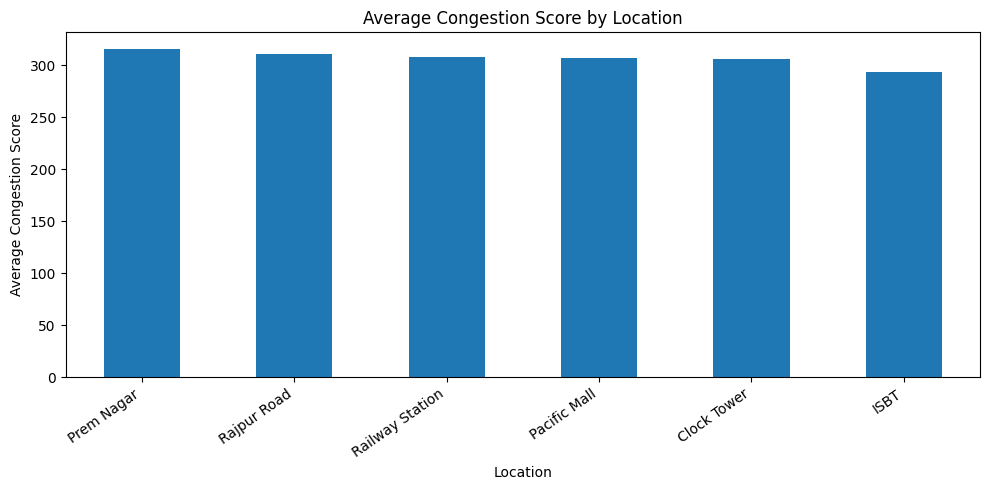

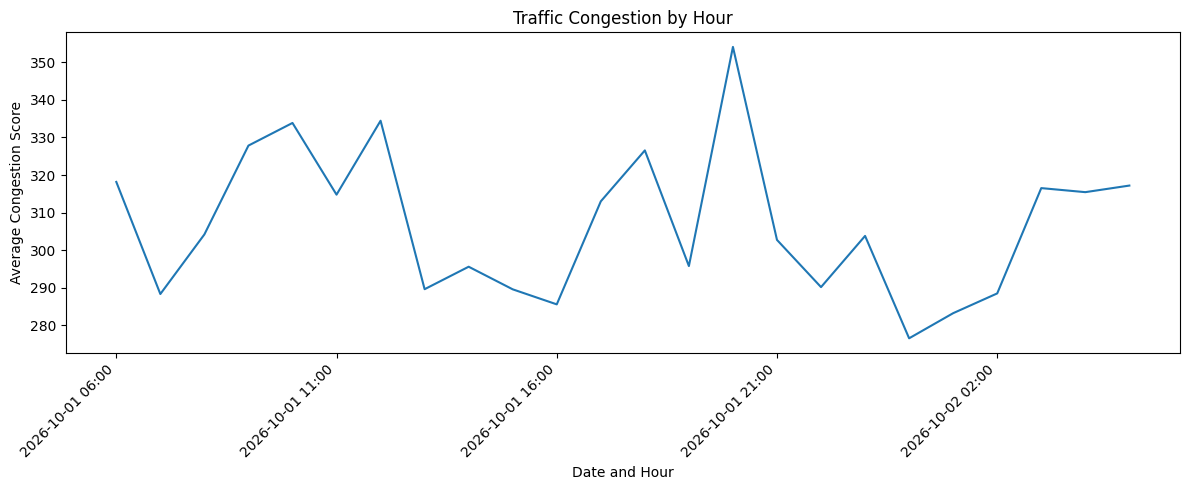

In [4]:

import matplotlib.pyplot as plt

location_summary = (
    results_df.groupby("location")["congestion_score"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
location_summary.plot(kind="bar")
plt.title("Average Congestion Score by Location")
plt.xlabel("Location")
plt.ylabel("Average Congestion Score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

hourly_summary = (
    results_df.groupby("hour")["congestion_score"]
    .mean()
)

plt.figure(figsize=(12, 5))
hourly_summary.plot()
plt.title("Traffic Congestion by Hour")
plt.xlabel("Date and Hour")
plt.ylabel("Average Congestion Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [5]:

import sqlite3
from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

DB_PATH = "data/traffic.db"

def get_connection():
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    return conn

with get_connection() as conn:
    conn.execute("""
        CREATE TABLE IF NOT EXISTS traffic_records (
            record_id INTEGER PRIMARY KEY,
            location TEXT NOT NULL,
            timestamp TEXT NOT NULL,
            vehicle_count INTEGER NOT NULL,
            avg_speed REAL NOT NULL
        )
    """)

    conn.execute("""
        CREATE TABLE IF NOT EXISTS analysis_results (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            location TEXT NOT NULL,
            hour TEXT NOT NULL,
            total_vehicles INTEGER NOT NULL,
            average_speed REAL NOT NULL,
            congestion_score REAL NOT NULL,
            record_count INTEGER NOT NULL
        )
    """)

    conn.execute("""
        CREATE TABLE IF NOT EXISTS analysis_runs (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            dataset_size INTEGER,
            processing_time REAL,
            status TEXT,
            created_at TEXT DEFAULT CURRENT_TIMESTAMP
        )
    """)

    traffic_df.to_sql(
        "traffic_records", conn,
        if_exists="replace", index=False
    )

    results_df.to_sql(
        "analysis_results", conn,
        if_exists="replace", index=False
    )

    conn.execute("""
        INSERT INTO analysis_runs
        (dataset_size, processing_time, status)
        VALUES (?, ?, ?)
    """, (len(traffic_df), processing_time, "SUCCESS"))

print("Database created and populated successfully!")

with get_connection() as conn:
    for table in [
        "traffic_records",
        "analysis_results",
        "analysis_runs"
    ]:
        count = conn.execute(
            f"SELECT COUNT(*) FROM {table}"
        ).fetchone()[0]
        print(f"{table}: {count} rows")


Database created and populated successfully!
traffic_records: 10000 rows
analysis_results: 144 rows
analysis_runs: 1 rows


In [6]:

from fastapi import FastAPI, Header, HTTPException, Body, Query
from fastapi.testclient import TestClient
from datetime import datetime
import pandas as pd
import time
import logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("traffic-analyzer")

app = FastAPI(
    title="MapReduce Traffic Analyzer API",
    description="Traffic congestion analytics using MapReduce",
    version="1.0.0"
)

API_KEY = "traffic-demo-2026"

def verify_api_key(x_api_key):
    if x_api_key != API_KEY:
        raise HTTPException(
            status_code=401,
            detail="Invalid or missing API key"
        )

@app.get("/health")
def health():
    return {"status": "healthy", "service": "Traffic Analyzer"}

@app.post("/traffic/upload")
def upload_traffic(
    records: list[dict] = Body(...),
    x_api_key: str = Header(default="")
):
    verify_api_key(x_api_key)

    required = {
        "record_id", "location", "timestamp",
        "vehicle_count", "avg_speed"
    }

    if not records:
        raise HTTPException(400, "No records provided")

    for record in records:
        if not required.issubset(record.keys()):
            raise HTTPException(
                400, "Missing required traffic columns"
            )

        try:
            if (int(record["vehicle_count"]) < 0
                    or float(record["avg_speed"]) <= 0):
                raise ValueError("Invalid values")
        except (ValueError, TypeError):
            raise HTTPException(
                400, "Vehicle count must be non-negative "
                     "and speed must be positive"
            )

    with get_connection() as conn:
        for record in records:
            conn.execute("""
                INSERT OR IGNORE INTO traffic_records
                (record_id, location, timestamp,
                 vehicle_count, avg_speed)
                VALUES (?, ?, ?, ?, ?)
            """, (
                int(record["record_id"]),
                str(record["location"]),
                str(record["timestamp"]),
                int(record["vehicle_count"]),
                float(record["avg_speed"])
            ))

    logger.info("Upload request received: %d records", len(records))

    return {
        "message": "Upload processed",
        "records_received": len(records)
    }

@app.post("/analysis/run")
def run_analysis(x_api_key: str = Header(default="")):
    verify_api_key(x_api_key)
    start = time.perf_counter()

    try:
        with get_connection() as conn:
            df = pd.read_sql_query(
                "SELECT * FROM traffic_records", conn
            )

        if df.empty:
            raise HTTPException(400, "No traffic data available")

        mapped_data = map_traffic_records(df)
        grouped_data = shuffle_and_group(mapped_data)
        output = reduce_traffic_records(grouped_data)

        elapsed = time.perf_counter() - start

        with get_connection() as conn:
            output.to_sql(
                "analysis_results", conn,
                if_exists="replace", index=False
            )

            conn.execute("""
                INSERT INTO analysis_runs
                (dataset_size, processing_time, status)
                VALUES (?, ?, ?)
            """, (len(df), elapsed, "SUCCESS"))

        logger.info(
            "Analysis completed: %d records in %.4f seconds",
            len(df), elapsed
        )

        return {
            "status": "success",
            "records_processed": len(df),
            "groups_created": len(output),
            "processing_time_seconds": round(elapsed, 4)
        }

    except HTTPException:
        raise
    except Exception:
        logger.exception("Analysis failed")
        with get_connection() as conn:
            conn.execute("""
                INSERT INTO analysis_runs
                (dataset_size, processing_time, status)
                VALUES (?, ?, ?)
            """, (0, time.perf_counter() - start, "FAILED"))

        raise HTTPException(
            500, "Analysis failed. Check application logs."
        )

@app.get("/analysis/results")
def get_results(
    limit: int = Query(default=20, ge=1, le=1000),
    x_api_key: str = Header(default="")
):
    verify_api_key(x_api_key)

    with get_connection() as conn:
        rows = conn.execute("""
            SELECT * FROM analysis_results
            ORDER BY congestion_score DESC LIMIT ?
        """, (limit,)).fetchall()

    return {"results": [dict(row) for row in rows]}

@app.get("/analysis/locations")
def get_locations(x_api_key: str = Header(default="")):
    verify_api_key(x_api_key)

    with get_connection() as conn:
        rows = conn.execute("""
            SELECT location,
                   ROUND(AVG(congestion_score), 2)
                       AS average_congestion,
                   SUM(total_vehicles) AS total_vehicles
            FROM analysis_results
            GROUP BY location
            ORDER BY average_congestion DESC
        """).fetchall()

    return {"locations": [dict(row) for row in rows]}

@app.get("/metrics")
def get_metrics(x_api_key: str = Header(default="")):
    verify_api_key(x_api_key)

    with get_connection() as conn:
        row = conn.execute("""
            SELECT dataset_size, processing_time, status,
                   created_at
            FROM analysis_runs
            ORDER BY id DESC LIMIT 1
        """).fetchone()

    if row is None:
        return {"message": "No analysis runs recorded"}

    data = dict(row)
    elapsed = data["processing_time"] or 0

    data["records_per_second"] = round(
        data["dataset_size"] / elapsed, 2
    ) if elapsed > 0 else None

    return data

client = TestClient(app)

print("FastAPI application created!")
print("Available endpoints:")
for route in app.routes:
    if hasattr(route, "methods"):
        print(",".join(sorted(route.methods)), route.path)


FastAPI application created!
Available endpoints:
GET,HEAD /openapi.json
GET,HEAD /docs
GET,HEAD /docs/oauth2-redirect
GET,HEAD /redoc
GET /health
POST /traffic/upload
POST /analysis/run
GET /analysis/results
GET /analysis/locations
GET /metrics


In [7]:

headers = {"X-API-Key": API_KEY}

response = client.get("/health")
print("1. Health:", response.status_code, response.json())

new_records = [
    {
        "record_id": 10001,
        "location": "Clock Tower",
        "timestamp": "2026-10-11 09:00:00",
        "vehicle_count": 220,
        "avg_speed": 9.5
    },
    {
        "record_id": 10002,
        "location": "Rajpur Road",
        "timestamp": "2026-10-11 09:00:00",
        "vehicle_count": 80,
        "avg_speed": 38.0
    }
]

response = client.post(
    "/traffic/upload",
    json=new_records,
    headers=headers
)
print("2. Upload:", response.status_code, response.json())

response = client.post("/analysis/run", headers=headers)
print("3. Analysis:", response.status_code, response.json())

response = client.get(
    "/analysis/results?limit=5", headers=headers
)
print("4. Results:", response.status_code)
display(pd.DataFrame(response.json()["results"]))

response = client.get("/analysis/locations", headers=headers)
print("5. Locations:", response.status_code)
display(pd.DataFrame(response.json()["locations"]))

response = client.get("/metrics", headers=headers)
print("6. Metrics:", response.status_code, response.json())

response = client.get("/analysis/results")
print("Security test:", response.status_code)


1. Health: 200 {'status': 'healthy', 'service': 'Traffic Analyzer'}
2. Upload: 200 {'message': 'Upload processed', 'records_received': 2}
3. Analysis: 200 {'status': 'success', 'records_processed': 10002, 'groups_created': 146, 'processing_time_seconds': 6.3774}
4. Results: 200


,location,hour,total_vehicles,average_speed,congestion_score,record_count
0,Rajpur Road,2026-10-01 20:00,12955,28.40,456.10,88
1,Railway Station,2026-10-01 10:00,12205,28.62,426.47,84
2,Rajpur Road,2026-10-01 19:00,12123,29.18,415.39,85
3,Railway Station,2026-10-02 03:00,11932,28.76,414.83,81
4,Railway Station,2026-10-01 08:00,11734,29.16,402.45,81


5. Locations: 200


,location,average_congestion,total_vehicles
0,Prem Nagar,315.80,231685
1,Railway Station,307.84,225657
2,Pacific Mall,307.40,224765
3,Rajpur Road,298.72,229477
4,Clock Tower,294.40,225748
5,ISBT,293.59,214899


6. Metrics: 200 {'dataset_size': 10002, 'processing_time': 6.3773617629999535, 'status': 'SUCCESS', 'created_at': '2026-10-11 16:19:04', 'records_per_second': 1568.36}
Security test: 401


In [8]:

import time
import pandas as pd
from IPython.display import display

benchmark_results = []

for size in [1000, 10000, 100000]:
    print(f"Testing {size:,} records...")

    test_df = generate_traffic_data(size)

    start = time.perf_counter()

    mapped = map_traffic_records(test_df)
    grouped = shuffle_and_group(mapped)
    reduced = reduce_traffic_records(grouped)

    elapsed = time.perf_counter() - start

    benchmark_results.append({
        "Dataset Size": size,
        "Groups": len(reduced),
        "Processing Time (seconds)": round(elapsed, 4),
        "Throughput (records/second)": round(size / elapsed, 2)
    })

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df.to_csv(
    "results/performance_benchmark.csv", index=False
)

display(benchmark_df)

print("Benchmark results saved successfully!")


Testing 1,000 records...
Testing 10,000 records...
Testing 100,000 records...


,Dataset Size,Groups,Processing Time (seconds),Throughput (records/second)
0,1000,144,0.0765,13066.53
1,10000,144,0.6647,15044.10
2,100000,144,7.6607,13053.67


Benchmark results saved successfully!


In [9]:

invalid_record = {
    "record_id": 20001,
    "location": "Test Road"
}

response = client.post(
    "/traffic/upload",
    json=[invalid_record],
    headers={"X-API-Key": API_KEY}
)

print("Invalid upload status:", response.status_code)
print("Failure response:", response.json())

response = client.get("/health")

print("Recovery health check:", response.status_code)
print(response.json())


Invalid upload status: 400
Failure response: {'detail': 'Missing required traffic columns'}
Recovery health check: 200
{'status': 'healthy', 'service': 'Traffic Analyzer'}


,Dataset Size,Output Groups,Processing Time (seconds),Throughput (records/second)
0,1000,144,0.0731,13688.30
1,10000,144,0.6459,15481.54
2,100000,144,7.7005,12986.12


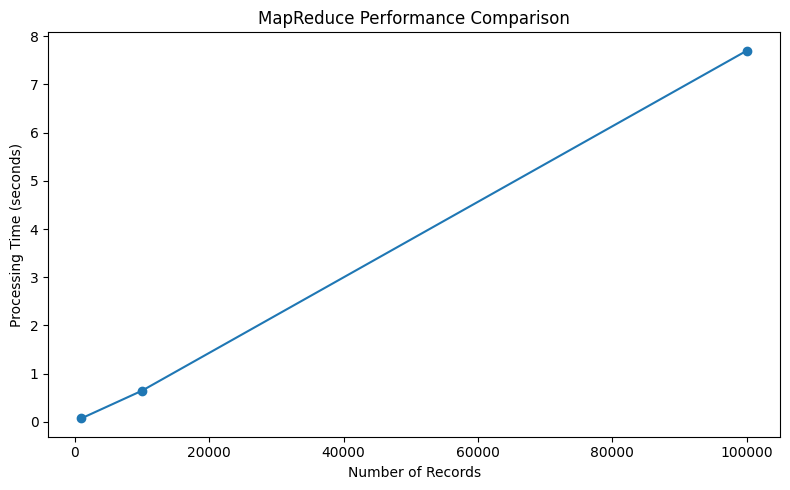

Benchmark saved successfully!


In [10]:

import time
import pandas as pd
import matplotlib.pyplot as plt

benchmark_results = []

for size in [1000, 10000, 100000]:
    df_test = generate_traffic_data(size)

    start = time.perf_counter()

    mapped_test = map_traffic_records(df_test)
    grouped_test = shuffle_and_group(mapped_test)
    reduced_test = reduce_traffic_records(grouped_test)

    elapsed = time.perf_counter() - start

    benchmark_results.append({
        "Dataset Size": size,
        "Output Groups": len(reduced_test),
        "Processing Time (seconds)": round(elapsed, 4),
        "Throughput (records/second)": round(size / elapsed, 2)
    })

benchmark_df = pd.DataFrame(benchmark_results)
display(benchmark_df)

benchmark_df.to_csv(
    "results/performance_benchmark.csv", index=False
)

plt.figure(figsize=(8, 5))
plt.plot(
    benchmark_df["Dataset Size"],
    benchmark_df["Processing Time (seconds)"],
    marker="o"
)
plt.xlabel("Number of Records")
plt.ylabel("Processing Time (seconds)")
plt.title("MapReduce Performance Comparison")
plt.tight_layout()
plt.show()

print("Benchmark saved successfully!")


,Workload,Concurrent Workers,Total Requests,Successful Requests,Total Time (seconds),Average Latency (ms)
0,Low,5,50,50,0.1536,14.68
1,Medium,20,50,50,0.1609,50.09
2,High,50,50,50,0.2198,66.37


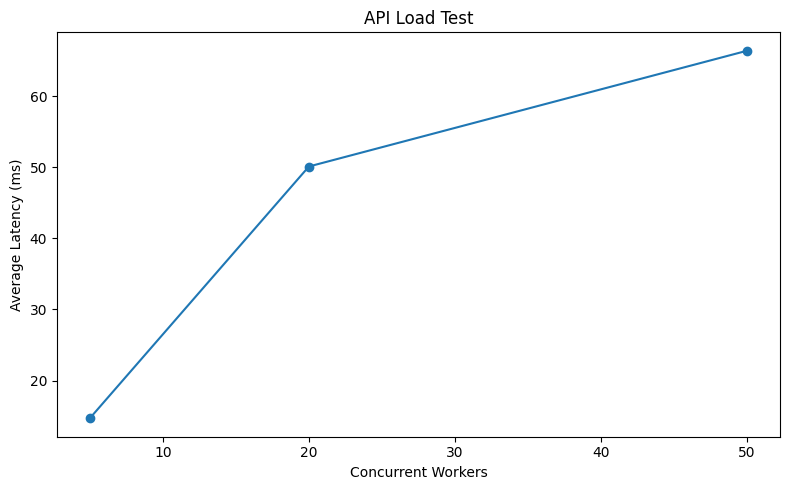

Load test completed.


In [11]:

from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd
import matplotlib.pyplot as plt

def make_request(_):
    start = time.perf_counter()
    response = client.get("/health")
    elapsed = time.perf_counter() - start
    return response.status_code, elapsed

load_results = []

for level, workers in [
    ("Low", 5),
    ("Medium", 20),
    ("High", 50)
]:
    total_requests = 50

    start = time.perf_counter()

    with ThreadPoolExecutor(max_workers=workers) as pool:
        responses = list(pool.map(make_request, range(total_requests)))

    total_time = time.perf_counter() - start
    latencies = [r[1] for r in responses]
    success_count = sum(r[0] == 200 for r in responses)

    load_results.append({
        "Workload": level,
        "Concurrent Workers": workers,
        "Total Requests": total_requests,
        "Successful Requests": success_count,
        "Total Time (seconds)": round(total_time, 4),
        "Average Latency (ms)": round(
            sum(latencies) / len(latencies) * 1000, 2
        )
    })

load_df = pd.DataFrame(load_results)
display(load_df)

load_df.to_csv("results/load_test.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(
    load_df["Concurrent Workers"],
    load_df["Average Latency (ms)"],
    marker="o"
)
plt.xlabel("Concurrent Workers")
plt.ylabel("Average Latency (ms)")
plt.title("API Load Test")
plt.tight_layout()
plt.show()

print("Load test completed.")


In [12]:

%%writefile mapreduce.py

import pandas as pd
from collections import defaultdict


def map_traffic_records(df):

    mapped_data = []

    for _, row in df.iterrows():
        timestamp = pd.to_datetime(row["timestamp"])
        hour = timestamp.strftime("%Y-%m-%d %H:00")
        key = (str(row["location"]), hour)

        value = {
            "vehicle_count": int(row["vehicle_count"]),
            "speed": float(row["avg_speed"])
        }

        mapped_data.append((key, value))

    return mapped_data


def shuffle_and_group(mapped_data):

    grouped_data = defaultdict(list)

    for key, value in mapped_data:
        grouped_data[key].append(value)

    return grouped_data


def reduce_traffic_records(grouped_data):

    results = []

    for (location, hour), values in grouped_data.items():
        total_vehicles = sum(
            item["vehicle_count"] for item in values
        )

        average_speed = sum(
            item["speed"] for item in values
        ) / len(values)

        congestion_score = total_vehicles / max(average_speed, 1)

        results.append({
            "location": location,
            "hour": hour,
            "total_vehicles": total_vehicles,
            "average_speed": round(average_speed, 2),
            "congestion_score": round(congestion_score, 2),
            "record_count": len(values)
        })

    return pd.DataFrame(results)


def analyze_traffic(df):

    mapped = map_traffic_records(df)
    grouped = shuffle_and_group(mapped)
    results = reduce_traffic_records(grouped)

    return results


Writing mapreduce.py


In [13]:

%%writefile database.py

import os
import sqlite3
import pandas as pd

DB_PATH = os.getenv("DB_PATH", "traffic.db")


def get_connection():
    conn = sqlite3.connect(DB_PATH, timeout=30)
    conn.row_factory = sqlite3.Row
    return conn


def initialize_database():
    with get_connection() as conn:
        conn.execute("""
            CREATE TABLE IF NOT EXISTS traffic_records (
                record_id INTEGER PRIMARY KEY,
                location TEXT NOT NULL,
                timestamp TEXT NOT NULL,
                vehicle_count INTEGER NOT NULL,
                avg_speed REAL NOT NULL
            )
        """)

        conn.execute("""
            CREATE TABLE IF NOT EXISTS analysis_results (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                location TEXT NOT NULL,
                hour TEXT NOT NULL,
                total_vehicles INTEGER NOT NULL,
                average_speed REAL NOT NULL,
                congestion_score REAL NOT NULL,
                record_count INTEGER NOT NULL
            )
        """)

        conn.execute("""
            CREATE TABLE IF NOT EXISTS analysis_runs (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                dataset_size INTEGER,
                processing_time REAL,
                status TEXT,
                created_at TEXT DEFAULT CURRENT_TIMESTAMP
            )
        """)


def save_traffic_records(records):
    with get_connection() as conn:
        conn.executemany("""
            INSERT OR REPLACE INTO traffic_records
            (record_id, location, timestamp,
             vehicle_count, avg_speed)
            VALUES (?, ?, ?, ?, ?)
        """, [
            (
                r["record_id"], r["location"], r["timestamp"],
                r["vehicle_count"], r["avg_speed"]
            )
            for r in records
        ])


def load_traffic_records():
    with get_connection() as conn:
        return pd.read_sql_query(
            "SELECT * FROM traffic_records", conn
        )


def save_analysis_results(results):
    with get_connection() as conn:
        conn.execute("DELETE FROM analysis_results")

        results.to_sql(
            "analysis_results",
            conn,
            if_exists="append",
            index=False
        )


def record_analysis_run(size, elapsed, status):
    with get_connection() as conn:
        conn.execute("""
            INSERT INTO analysis_runs
            (dataset_size, processing_time, status)
            VALUES (?, ?, ?)
        """, (size, elapsed, status))


Writing database.py


In [14]:

%%writefile main.py

import os
import time
import logging
import pandas as pd

from fastapi import FastAPI, Header, HTTPException, Query
from pydantic import BaseModel, Field
from datetime import datetime

from mapreduce import analyze_traffic
from database import (
    initialize_database,
    get_connection,
    save_traffic_records,
    load_traffic_records,
    save_analysis_results,
    record_analysis_run
)

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("traffic-analyzer")

API_KEY = os.getenv("API_KEY", "local-demo-key")

app = FastAPI(
    title="MapReduce Traffic Analyzer",
    description="Traffic congestion analysis API",
    version="1.0.0"
)


@app.on_event("startup")
def startup():
    initialize_database()
    logger.info("Traffic Analyzer API started")


def verify_api_key(x_api_key):
    if x_api_key != API_KEY:
        raise HTTPException(
            status_code=401,
            detail="Invalid or missing API key"
        )


class TrafficRecord(BaseModel):
    record_id: int
    location: str = Field(min_length=1)
    timestamp: datetime
    vehicle_count: int = Field(ge=0)
    avg_speed: float = Field(gt=0)


@app.get("/health")
def health():
    return {"status": "healthy", "service": "Traffic Analyzer"}


@app.post("/traffic/upload")
def upload_traffic(
    records: list[TrafficRecord],
    x_api_key: str = Header(default="")
):
    verify_api_key(x_api_key)

    if not records:
        raise HTTPException(400, "No records provided")

    try:
        normalized = [
            {
                "record_id": r.record_id,
                "location": r.location,
                "timestamp": r.timestamp.isoformat(),
                "vehicle_count": r.vehicle_count,
                "avg_speed": r.avg_speed
            }
            for r in records
        ]

        save_traffic_records(normalized)

        logger.info("Accepted %d traffic records", len(normalized))

        return {
            "status": "success",
            "records_received": len(normalized)
        }

    except Exception:
        logger.exception("Traffic upload failed")
        raise HTTPException(500, "Could not store traffic records")


@app.post("/analysis/run")
def run_analysis(x_api_key: str = Header(default="")):
    verify_api_key(x_api_key)
    start = time.perf_counter()
    df = load_traffic_records()

    if df.empty:
        raise HTTPException(400, "No traffic data available")

    try:
        results = analyze_traffic(df)
        elapsed = time.perf_counter() - start

        save_analysis_results(results)
        record_analysis_run(len(df), elapsed, "SUCCESS")

        logger.info(
            "Processed %d records in %.4f seconds",
            len(df), elapsed
        )

        return {
            "status": "success",
            "records_processed": len(df),
            "groups_created": len(results),
            "processing_time_seconds": round(elapsed, 4)
        }

    except Exception:
        elapsed = time.perf_counter() - start
        record_analysis_run(len(df), elapsed, "FAILED")
        logger.exception("Analysis failed")
        raise HTTPException(500, "Analysis failed; check application logs")


@app.get("/analysis/results")
def get_results(
    limit: int = Query(default=20, ge=1, le=1000),
    x_api_key: str = Header(default="")
):
    verify_api_key(x_api_key)

    with get_connection() as conn:
        rows = conn.execute("""
            SELECT location, hour, total_vehicles,
                   average_speed, congestion_score, record_count
            FROM analysis_results
            ORDER BY congestion_score DESC
            LIMIT ?
        """, (limit,)).fetchall()

    return {"results": [dict(r) for r in rows]}


@app.get("/analysis/locations")
def get_locations(x_api_key: str = Header(default="")):
    verify_api_key(x_api_key)

    with get_connection() as conn:
        rows = conn.execute("""
            SELECT location,
                   ROUND(AVG(congestion_score), 2)
                       AS average_congestion,
                   SUM(total_vehicles) AS total_vehicles
            FROM analysis_results
            GROUP BY location
            ORDER BY average_congestion DESC
        """).fetchall()

    return {"locations": [dict(r) for r in rows]}


@app.get("/metrics")
def get_metrics(x_api_key: str = Header(default="")):
    verify_api_key(x_api_key)

    with get_connection() as conn:
        row = conn.execute("""
            SELECT dataset_size, processing_time, status, created_at
            FROM analysis_runs
            ORDER BY id DESC LIMIT 1
        """).fetchone()

    if row is None:
        return {"message": "No analysis runs recorded"}

    result = dict(row)
    elapsed = result["processing_time"] or 0

    result["records_per_second"] = (
        round(result["dataset_size"] / elapsed, 2)
        if elapsed > 0 else None
    )

    return result


Writing main.py


In [15]:

%%writefile requirements.txt
fastapi
uvicorn
pandas
numpy
pydantic


Writing requirements.txt


In [16]:

import os
os.environ["API_KEY"] = "local-demo-key"

from fastapi.testclient import TestClient
from main import app

client_new = TestClient(app)

response = client_new.get("/health")
print("Health:", response.status_code, response.json())

response = client_new.get("/analysis/results")
print("Authentication:", response.status_code, response.json())


Health: 200 {'status': 'healthy', 'service': 'Traffic Analyzer'}
Authentication: 401 {'detail': 'Invalid or missing API key'}


In [20]:

from database import (
    initialize_database,
    save_traffic_records,
    save_analysis_results,
    record_analysis_run,
    get_connection
)

import pandas as pd
import time

initialize_database()

records = traffic_df.copy()
records["timestamp"] = pd.to_datetime(
    records["timestamp"]
).map(lambda x: x.isoformat())

save_traffic_records(records.to_dict(orient="records"))

save_analysis_results(results_df)

record_analysis_run(
    len(traffic_df),
    processing_time,
    "SUCCESS"
)

with get_connection() as conn:
    for table in [
        "traffic_records",
        "analysis_results",
        "analysis_runs"
    ]:
        count = conn.execute(
            f"SELECT COUNT(*) FROM {table}"
        ).fetchone()[0]

        print(f"{table}: {count} rows")

print("Database initialized and populated successfully!")


traffic_records: 10000 rows
analysis_results: 144 rows
analysis_runs: 2 rows
Database initialized and populated successfully!


In [21]:

response = client_new.get(
    "/analysis/results",
    headers={"X-API-Key": "local-demo-key"}
)

print("Status:", response.status_code)
print(response.json())


Status: 200
{'results': [{'location': 'Rajpur Road', 'hour': '2026-10-01 20:00', 'total_vehicles': 12955, 'average_speed': 28.4, 'congestion_score': 456.1, 'record_count': 88}, {'location': 'Railway Station', 'hour': '2026-10-01 10:00', 'total_vehicles': 12205, 'average_speed': 28.62, 'congestion_score': 426.47, 'record_count': 84}, {'location': 'Rajpur Road', 'hour': '2026-10-01 19:00', 'total_vehicles': 12123, 'average_speed': 29.18, 'congestion_score': 415.39, 'record_count': 85}, {'location': 'Railway Station', 'hour': '2026-10-02 03:00', 'total_vehicles': 11932, 'average_speed': 28.76, 'congestion_score': 414.83, 'record_count': 81}, {'location': 'Railway Station', 'hour': '2026-10-01 08:00', 'total_vehicles': 11734, 'average_speed': 29.16, 'congestion_score': 402.45, 'record_count': 81}, {'location': 'Railway Station', 'hour': '2026-10-01 12:00', 'total_vehicles': 12064, 'average_speed': 30.01, 'congestion_score': 402.06, 'record_count': 88}, {'location': 'Clock Tower', 'hour': '

In [22]:

import os
import zipfile
from google.colab import files

project_files = [
    "main.py",
    "mapreduce.py",
    "database.py",
    "requirements.txt"
]

missing = [f for f in project_files if not os.path.exists(f)]
if missing:
    print("Missing files:", missing)
else:
    with zipfile.ZipFile(
        "mapreduce_traffic_analyzer.zip", "w"
    ) as z:
        for filename in project_files:
            z.write(filename)

    print("Project files packaged successfully!")
    files.download("mapreduce_traffic_analyzer.zip")


Project files packaged successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>